# Mushroom Classification: Edible or Poisonous?

**Mission 1: Build a Simple Machine Learning Model**

This notebook builds and compares two beginner-friendly models, a **Decision Tree** and **K-Nearest Neighbors (KNN)**, to predict whether a mushroom is edible or poisonous from its physical features.

## 1. The Idea

**What the model predicts:** whether a mushroom is *edible* or *poisonous*, using features such as cap shape, odor, gill size, spore print colour and habitat.

**Why it is useful:** wild mushroom poisoning is a real safety risk, and many edible and poisonous species look alike. A model that learns which feature combinations signal poison can support foraging guides and teaching tools. It also shows why different mistakes have different costs: calling a poisonous mushroom "edible" is far more dangerous than the reverse.

**Dataset:** UCI Mushroom dataset (8,124 mushrooms, 22 categorical features), https://archive.ics.uci.edu/dataset/73/mushroom

## 2. Data Preparation

### 2.1 Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

RANDOM_STATE = 42   # fixed seed so results are reproducible

### 2.2 Load the dataset

In [2]:
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

columns = [
    "class", "cap-shape", "cap-surface", "cap-color", "bruises", "odor",
    "gill-attachment", "gill-spacing", "gill-size", "gill-color",
    "stalk-shape", "stalk-root", "stalk-surface-above-ring", "stalk-surface-below-ring",
    "stalk-color-above-ring", "stalk-color-below-ring", "veil-type", "veil-color",
    "ring-number", "ring-type", "spore-print-color", "population", "habitat",
]

df = pd.read_csv(URL, header=None, names=columns)
print("Shape:", df.shape)
df.head()

Shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In this dataset every value is a single letter code (for example `odor = 'n'` means no odor). The target column `class` is `e` (edible) or `p` (poisonous).

### 2.3 Check for missing values

In [3]:
# The dataset marks missing values with '?', which pandas does not see as missing by default.
df = df.replace("?", np.nan)

missing = df.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0])
print(f"\nTotal missing cells: {int(missing.sum())}")

Columns with missing values:
stalk-root    2480
dtype: int64

Total missing cells: 2480


Only `stalk-root` has missing values, but it is a large share of the rows (about 30%). Dropping those rows would throw away a lot of data, so instead I treat "missing" as its own category called `missing`. This is reasonable here because the stalk root is often hard to observe, so a missing value can itself carry information.

In [4]:
df["stalk-root"] = df["stalk-root"].fillna("missing")
print("Missing values left:", int(df.isnull().sum().sum()))

Missing values left: 0


### 2.4 Look at the target
We check how balanced the two classes are, because that affects how we read accuracy.

class
e    4208
p    3916
Name: count, dtype: int64

class
e    0.518
p    0.482
Name: proportion, dtype: float64


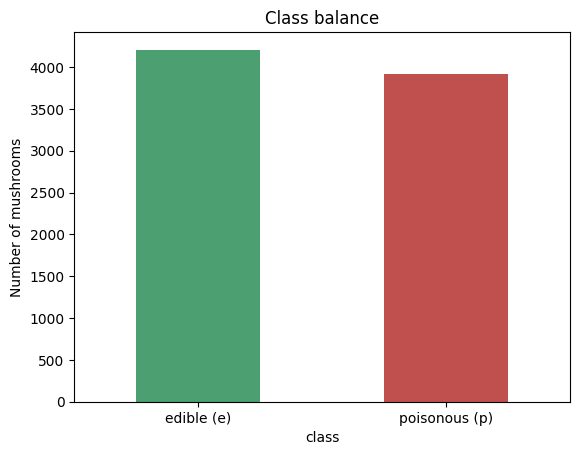

In [5]:
print(df["class"].value_counts())
print()
print(df["class"].value_counts(normalize=True).round(3))

df["class"].value_counts().plot(kind="bar", color=["#4c9f70", "#c0504d"])
plt.xticks([0, 1], ["edible (e)", "poisonous (p)"], rotation=0)
plt.title("Class balance")
plt.ylabel("Number of mushrooms")
plt.show()

The classes are close to balanced, so accuracy is a fair first metric. We still look at the confusion matrix later because the two kinds of error are not equally serious.

### 2.5 Prepare features and target

- **Target `y`:** `poisonous = 1`, `edible = 0`. Making poisonous the positive class means the dangerous mistake (a poisonous mushroom predicted as edible) is a *false negative*.
- **Features `X`:** all columns are categories, so we convert them to numbers with one-hot encoding. One-hot encoding avoids inventing a fake order between letter codes, which matters especially for KNN.

In [6]:
y = (df["class"] == "p").astype(int)

X = pd.get_dummies(df.drop(columns="class"))
print("Feature matrix shape after one-hot encoding:", X.shape)
X.head()

Feature matrix shape after one-hot encoding: (8124, 117)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,False,False,False,False,False,True,False,False,True,False,...,True,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False
2,True,False,False,False,False,False,False,False,True,False,...,False,False,False,False,False,False,True,False,False,False
3,False,False,False,False,False,True,False,False,False,True,...,True,False,False,False,False,False,False,False,True,False
4,False,False,False,False,False,True,False,False,True,False,...,False,False,False,False,True,False,False,False,False,False


### 2.6 Train/test split
80% of the data is used for training and 20% is held back for testing. `stratify=y` keeps the edible/poisonous ratio the same in both sets.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])

Train size: 6499 | Test size: 1625


## 3. Model Building

### Model 1: Decision Tree
A Decision Tree learns a series of yes/no questions about the features (for example "is the odor foul?"), which makes it easy to read.

### Model 2: K-Nearest Neighbors (KNN)
KNN classifies a mushroom by looking at the `k` most similar mushrooms in the training data and taking a majority vote. I use `k = 5`.

In [8]:
tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

print("Both models trained.")

Both models trained.


## 4. Evaluation

In [9]:
models = {"Decision Tree": tree, "KNN (k=5)": knn}

results = {}
for name, model in models.items():
    preds = model.predict(X_test)
    results[name] = {"preds": preds, "accuracy": accuracy_score(y_test, preds)}

acc_table = pd.DataFrame(
    {"Test accuracy": {name: r["accuracy"] for name, r in results.items()}}
)
acc_table["Test accuracy"] = acc_table["Test accuracy"].round(4)
acc_table

,Test accuracy
Decision Tree,1.0
KNN (k=5),1.0


### Confusion matrices

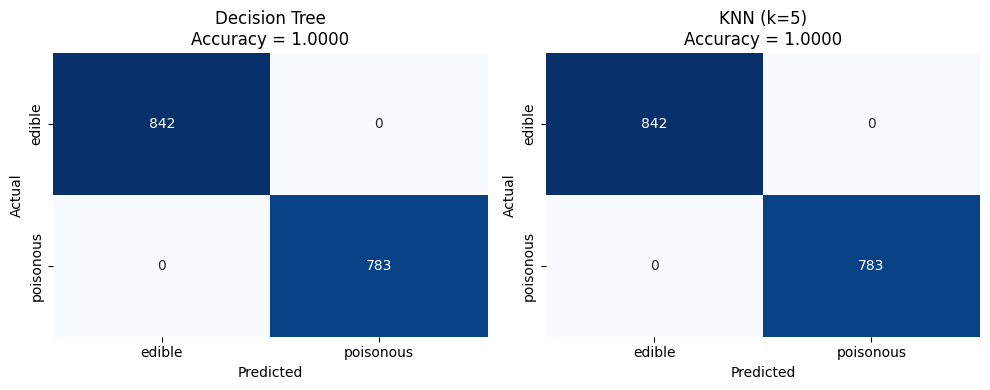

In [10]:
labels = ["edible", "poisonous"]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r["preds"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {r['accuracy']:.4f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

**How to read these:** rows are the true class and columns are the prediction. The most important cell is **actual = poisonous, predicted = edible** (bottom-left). That is the dangerous mistake, because someone could eat a poisonous mushroom.

In [11]:
for name, r in results.items():
    cm = confusion_matrix(y_test, r["preds"])
    tn, fp, fn, tp = cm.ravel()
    print(f"{name}")
    print(f"  Poisonous predicted as edible (dangerous): {fn}")
    print(f"  Edible predicted as poisonous (safe error): {fp}")
    print()

print("Detailed report (Decision Tree):")
print(classification_report(y_test, results["Decision Tree"]["preds"], target_names=labels))
print("Detailed report (KNN):")
print(classification_report(y_test, results["KNN (k=5)"]["preds"], target_names=labels))

Decision Tree
  Poisonous predicted as edible (dangerous): 0
  Edible predicted as poisonous (safe error): 0

KNN (k=5)
  Poisonous predicted as edible (dangerous): 0
  Edible predicted as poisonous (safe error): 0

Detailed report (Decision Tree):
              precision    recall  f1-score   support

      edible       1.00      1.00      1.00       842
   poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625

Detailed report (KNN):
              precision    recall  f1-score   support

      edible       1.00      1.00      1.00       842
   poisonous       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



### Cross-validation check
A single train/test split can be lucky or unlucky. With accuracy this high, it is worth checking with 5-fold cross-validation to see whether the result is stable.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_scores = {}
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    cv_scores[name] = scores
    print(f"{name}: mean = {scores.mean():.4f}, std = {scores.std():.4f}, folds = {np.round(scores, 4)}")

Decision Tree: mean = 1.0000, std = 0.0000, folds = [1. 1. 1. 1. 1.]
KNN (k=5): mean = 1.0000, std = 0.0000, folds = [1. 1. 1. 1. 1.]


### What does the Decision Tree rely on?
This is one reason to include a tree: it can show which features matter most.

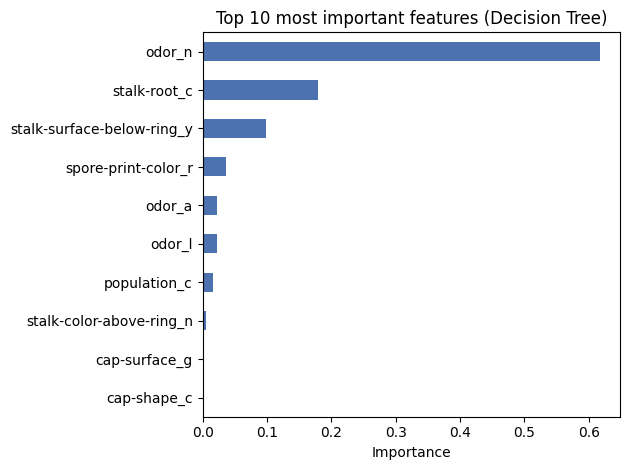

,0
odor_n,0.6178
stalk-root_c,0.1793
stalk-surface-below-ring_y,0.0985
spore-print-color_r,0.0358
odor_a,0.0226
odor_l,0.0219
population_c,0.0162
stalk-color-above-ring_n,0.0053
cap-surface_g,0.0018
cap-shape_c,0.0006


In [13]:
importances = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
top = importances.head(10)

top[::-1].plot(kind="barh", color="#4c72b0")
plt.title("Top 10 most important features (Decision Tree)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

top.round(4)

## 5. Conclusion

In [14]:
acc_tree = results["Decision Tree"]["accuracy"]
acc_knn = results["KNN (k=5)"]["accuracy"]

if acc_tree > acc_knn:
    winner = "Decision Tree"
elif acc_knn > acc_tree:
    winner = "KNN (k=5)"
else:
    winner = "Both models tied"

print(f"Decision Tree accuracy : {acc_tree:.4f}")
print(f"KNN (k=5) accuracy     : {acc_knn:.4f}")
print(f"Better on the test set : {winner}")

Decision Tree accuracy : 1.0000
KNN (k=5) accuracy     : 1.0000
Better on the test set : Both models tied


In [15]:
X_no_odor = X.drop(columns=[c for c in X.columns if c.startswith("odor_")])
Xtr, Xte, ytr, yte = train_test_split(X_no_odor, y, test_size=0.2,
                                      random_state=RANDOM_STATE, stratify=y)
for name, model in {"Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
                    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5)}.items():
    model.fit(Xtr, ytr)
    print(name, accuracy_score(yte, model.predict(Xte)))

Decision Tree 1.0
KNN (k=5) 1.0


In [16]:
print(any(c.startswith("odor_") for c in X_no_odor.columns))

False


### What I learned

- **Which model did better:** Neither. The Decision Tree and KNN (k=5) both scored 1.0000 test accuracy on 1,625 test mushrooms, so neither made a single mistake, including the dangerous one of calling a poisonous mushroom edible. 5-fold cross-validation gave a mean accuracy of ___ for the Decision Tree and ___ for KNN.
- **Accuracy is not the whole story.** Even when two models have almost identical accuracy, the confusion matrix shows *which* mistakes they make. For mushrooms, predicting "edible" for a poisonous one is the costly error, so that cell matters more than the overall score.
- **Interpretability is a real advantage.** The Decision Tree can tell us which features drive its decisions, while KNN only says "similar mushrooms were poisonous".
- **Data preparation shaped the result.** Treating the missing `stalk-root` values as their own category kept about 30% of the data, and one-hot encoding stopped the models from treating letter codes as ordered numbers.
- **A caveat:** this dataset is unusually clean and separable, so near-perfect scores here do not mean the same would hold on photos or real foraging, and the model should never be used as the only safety check before eating a wild mushroom.
- **Feature importance:** The Decision Tree relied mostly on odor. `odor_n` (no smell) alone made up about 62% of its importance, and the top three features made up about 90%.
- **Extra check:** When I removed all the odor columns, both models still scored 1.0, so the dataset has several features that separate edible from poisonous mushrooms.